# Data Generation

## Imports

In [55]:
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
import matplotlib.pyplot as plt

## Directories

In [56]:
notebooks_dir = os.getcwd()
base_dir = os.path.join(notebooks_dir, '..')

data_dir = os.path.join(base_dir, 'data')
smart_meter_data_dir = os.path.join(data_dir, 'smart_meter_data')

processed_data_dir = os.path.join(base_dir, 'processed_data')
os.makedirs(processed_data_dir, exist_ok=True)

## Data generation settings

`T_limit` sets the maximum number of timestamps in the datastet. We also specify the proportionals of data assigned to the training, validation, and testing sets, along with the window length and stride used to create input windows. The stride determines how far the window moves between steps. 

With `stride=30`, stride is equal to the window length, producing non-overlapping windows. We will use this for our simple pattern-matching method.

With `stride=1`, each new window starts one timestamp later, so consecutive windows overap as much as possible. This is useful for sequence-to-point models, which pair each input window with a target value. A stride of 1 helps create a target for each step in the sequence. Finally, we set the chunk size used when randomly assigning data to the training, validation, and testing sets. Each chunk must be at least as long as the window length.

In [57]:
T_limit = None
train_val_test_split = [0.7, 0.15, 0.15]
window_length, stride = 30, 30
chunk_size = 1440 # One-Day
time_resolution = 60
time_units = 'seconds'

## Load Data

We load pre-processed ampds data from [citation], which is stored in a matlab format. We load the aggregate data and appliance-level data arrays, as well as the labels. 

There are a total of `1048575` timestamps in the AMPds2 dataset. For a time-resolution of 60-seconds, this corresponds to 2 days of data. For the `mini` dataset, we take 1000 timestamps. For the `full` dataset, we take all twelve days. For the `full` dataset, we choose a `chunk_size` of one-day. This means entire days will be assigned to the training, validation, and testing splits.

In [58]:
ampds_folderpath = os.path.join(smart_meter_data_dir, 'ampds')
ampds_filepath = os.path.join(ampds_folderpath, 'ampds2.mat')

data = loadmat(ampds_filepath)

agg, apps = data['input'], data['output']
agg_labels, apps_labels = data['labelInp'], data['labelOut']

print(f'Aggregate Data Shape: {agg.shape}')
print(f'Appliance Data Shape: {apps.shape}')

electrical_quantities = [label.strip() for label in agg_labels.flatten()]
electrical_quantities = [quantity for quantity in electrical_quantities if quantity not in ("time", "id")]
appliance_names = [label.strip() for label in apps_labels.flatten()]
appliance_names = [name for name in appliance_names if name not in ("time", "id")]

print(f"Electrical Quantities: {electrical_quantities}")
print(f"Appliance Names: {appliance_names}")
print(f"Number of Appliances: {len(appliance_names)}")

Aggregate Data Shape: (1048575, 6)
Appliance Data Shape: (1048575, 22, 4)
Electrical Quantities: ['P-agg', 'I-agg', 'Q-agg', 'S-agg']
Appliance Names: ['RSE', 'GRE', 'B1E', 'BME', 'CWE', 'DWE', 'EQE', 'FRE', 'HPE', 'OFE', 'UTE', 'WOE', 'B2E', 'CDE', 'DNE', 'EBE', 'FGE', 'HTE', 'OUE', 'TVE']
Number of Appliances: 20


Both the aggregate and appliance-level data have four electrical quantities: Real Power $P$, Current Magnitdue $I$, Reactive Power $Q$, and Apparent Power $S$. The appliance-level data has also has 20 appliances. Both the aggregate and appliance-level data also have columns `'time'` and `'id'`. 

Next, we limit the size of the dataset by taking only the first `T_limit` number of timestamps. If no `T_limit` is defined, we keep all of the timestamps. For the aggregate data, we keep all four electrical quantities. For the appliance-level data, we keep only real power. We also double-check for missing values.

In [59]:
T = agg.shape[0]
T = min(T, T_limit) if T_limit is not None else T
num_chunks = T // chunk_size
print(f'Number of Chunks: {num_chunks}')

agg_dt, apps_dt = agg[:T], apps[:T, :, 0]  # For appliances, keep only real power P

datetimes, agg = agg_dt[:, 0], agg_dt[:, 2:]
apps = apps_dt[:, 2:]  # discard time and id, matching agg

agg_df = pd.DataFrame(agg_dt, columns=agg_labels)
apps_df = pd.DataFrame(apps_dt, columns=apps_labels)

total_missing = agg_df.isna().sum().sum() + apps_df.isna().sum().sum()
print(f"Total missing values: {total_missing}")

display(agg_df.head().style.format("{:.2f}").set_caption('Aggregate Measurements'))
display(apps_df.head().style.format("{:.2f}").set_caption('Appliance-Level Measurements'))

Number of Chunks: 728
Total missing values: 0


,time,id,P-agg,I-agg,Q-agg,S-agg
0,60.00,1.00,918.00,8.30,141.00,1037.00
1,120.00,1.00,913.00,8.20,141.00,1028.00
2,180.00,1.00,872.00,8.00,139.00,993.00
3,240.00,1.00,872.00,8.00,141.00,990.00
4,300.00,1.00,772.00,7.80,140.00,988.00


,time,id,RSE,GRE,B1E,BME,CWE,DWE,EQE,FRE,HPE,OFE,UTE,WOE,B2E,CDE,DNE,EBE,FGE,HTE,OUE,TVE
0,60.00,1.00,43.00,2.00,0.00,352.00,0.00,0.00,41.00,106.00,36.00,62.00,9.00,0.00,58.00,0.00,30.00,0.00,0.00,4.00,0.00,37.00
1,120.00,1.00,43.00,0.00,0.00,354.00,0.00,0.00,35.00,107.00,37.00,61.00,9.00,0.00,58.00,0.00,30.00,0.00,0.00,4.00,0.00,37.00
2,180.00,1.00,43.00,2.00,0.00,354.00,0.00,0.00,41.00,107.00,38.00,61.00,9.00,0.00,8.00,0.00,30.00,0.00,0.00,4.00,0.00,37.00
3,240.00,1.00,43.00,2.00,0.00,354.00,0.00,0.00,40.00,106.00,37.00,61.00,9.00,0.00,7.00,0.00,30.00,0.00,0.00,4.00,0.00,37.00
4,300.00,1.00,41.00,2.00,0.00,352.00,0.00,0.00,40.00,106.00,36.00,61.00,9.00,0.00,8.00,0.00,31.00,0.00,0.00,4.00,0.00,37.00


## Get Appliance Metrics

The AMPDS Dataset contains the following appliances:
- RSE: Basement rental suite sub-meter.
- GRE: Detatched garage sub-meter.
- B1E: North bedroom plugs and lights.
- B2E: Master and south bedroom plugs and lights.
- BME: Basement plugs and lights.
- CWE: Front-loading clothes washer.
- DWE: Kitchen dishwasher.
- EQE: Security and network equipment.
- FRE: Forces air furnace fan and thermostat.
- HPE: Heat pump.
- OFE: Home office plugs and lights.
- UTE: Utility room plug.
- WOE: Kitchen convenction wall oven.
- CDE: Clothes Dryer
- DNE: Dining room plugs.
- EBE: Electronics workbench.
- FGE: Kitchen fridge.
- HTE: Instant hot water unit.
- OUE: Outside plug.
- TVE: Entertainment equipment (TV, amplifier, Blu-Ray).
- UNE: Unmetered.

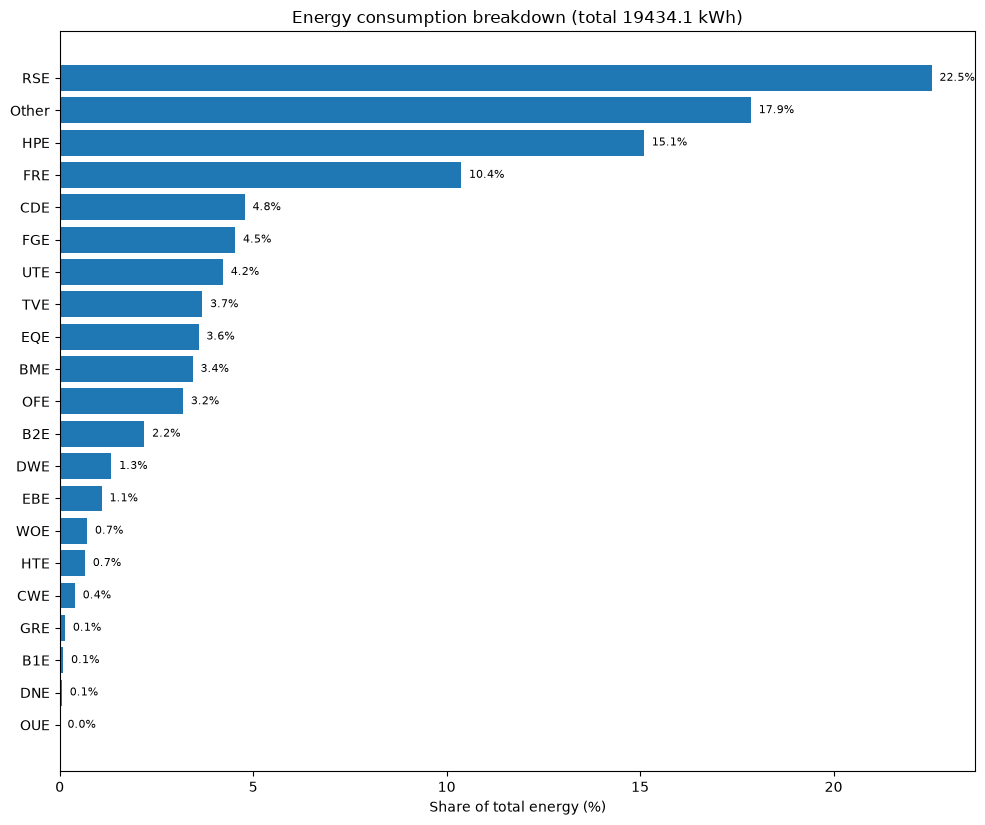

In [60]:
agg_energy_kwh = np.sum(agg[:, 0]) * time_resolution / 3.6e6  # aggregate real power P, W·s → kWh
app_energy = np.sum(apps, axis=0) * time_resolution / 3.6e6   # per appliance
other_energy = agg_energy_kwh - app_energy.sum()

energy = pd.Series(list(app_energy) + [other_energy], index=list(appliance_names) + ['Other'])
pct = (energy / agg_energy_kwh * 100).sort_values()

fig, ax = plt.subplots(figsize=(10, 0.35 * len(pct) + 1))
ax.barh(pct.index, pct.values, color='tab:blue')
for i, v in enumerate(pct.values):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=8)

ax.set_xlabel('Share of total energy (%)')
ax.set_title(f'Energy consumption breakdown (total {agg_energy_kwh:.1f} kWh)')
plt.tight_layout()
plt.show()

To make our dataset more representitive of a certain house, we may want to remove appliances from the dataset. Here, we remove the rental suite submeter from the appliance profiles, and subtract its profile from the aggregate power. 

In [ ]:
apps_to_remove = ['RSE']  # appliances to drop

remove_idx = [appliance_names.index(name) for name in apps_to_remove]
remove_cols = [i + 2 for i in remove_idx]  # offset for time/id columns

# Subtract removed appliances from aggregate real power
agg[:, 0] -= apps[:, remove_cols].sum(axis=1)

# Drop them from apps, apps_labels and appliance_names
keep_cols = [c for c in range(apps.shape[1]) if c not in remove_cols]
apps = apps[:, keep_cols]
apps_labels = np.asarray(apps_labels).flatten()[keep_cols]
appliance_names = [n for n in appliance_names if n not in apps_to_remove]


We are interested in a few key appliances with recgonizabe usage patterns, which are potentially shiftable or controllable, which makes identifying when they operate useful for energy managment. Because heating / cooling load comprises a large share of energy, we we select these appliances:
- Forced air-furnace fan and thermostat (FRE)
- Heat Pump (HPE)

We trim the appliance data (`apps`) and appliance name list (`appliance_names`) to include only these key deferrable loads.

In [62]:
deferrable_loads = ['FRE', 'HPE']
on_thresholds = np.array([1.0, 1.0])

appliance_indices = [appliance_names.index(name) for name in deferrable_loads]

apps = apps[:, appliance_indices]
apps_labels = np.asarray(apps_labels).flatten()[[0, 1] + [i + 2 for i in appliance_indices]]  # labels still include time/id
appliance_names = deferrable_loads

## Get Appliance Statistics

In NILM, some appliances are easier to predict than others. Appliances that are almost always on or almost always off can appear to have high prediction accuracy, even though their behavior is difficult to predict meaningfully. To better interpret our results, we should first characterize each appliance's load profile. For each appliance, we will calculate its minimum, maximum, mean, and median power, as well as its standard deviation.

`apps` is a 2D array containing time-series data for every appliance. The `get_appliance_metrics` function returns an array for each metric, ech array containing one value for each appliance.

In [63]:
def get_appliance_metrics(apps):
    return {
        "apps_min": np.min(apps, axis=0),
        "apps_max": np.max(apps, axis=0),
        "apps_mean": np.mean(apps, axis=0),
        "apps_median": np.median(apps, axis=0),
        "apps_std": np.std(apps, axis=0),
        'apps_energy': np.sum(apps, axis=0)}

In [64]:
appliance_metrics = get_appliance_metrics(apps)
metrics_df = pd.DataFrame(appliance_metrics, index=appliance_names)

## Visualize Data

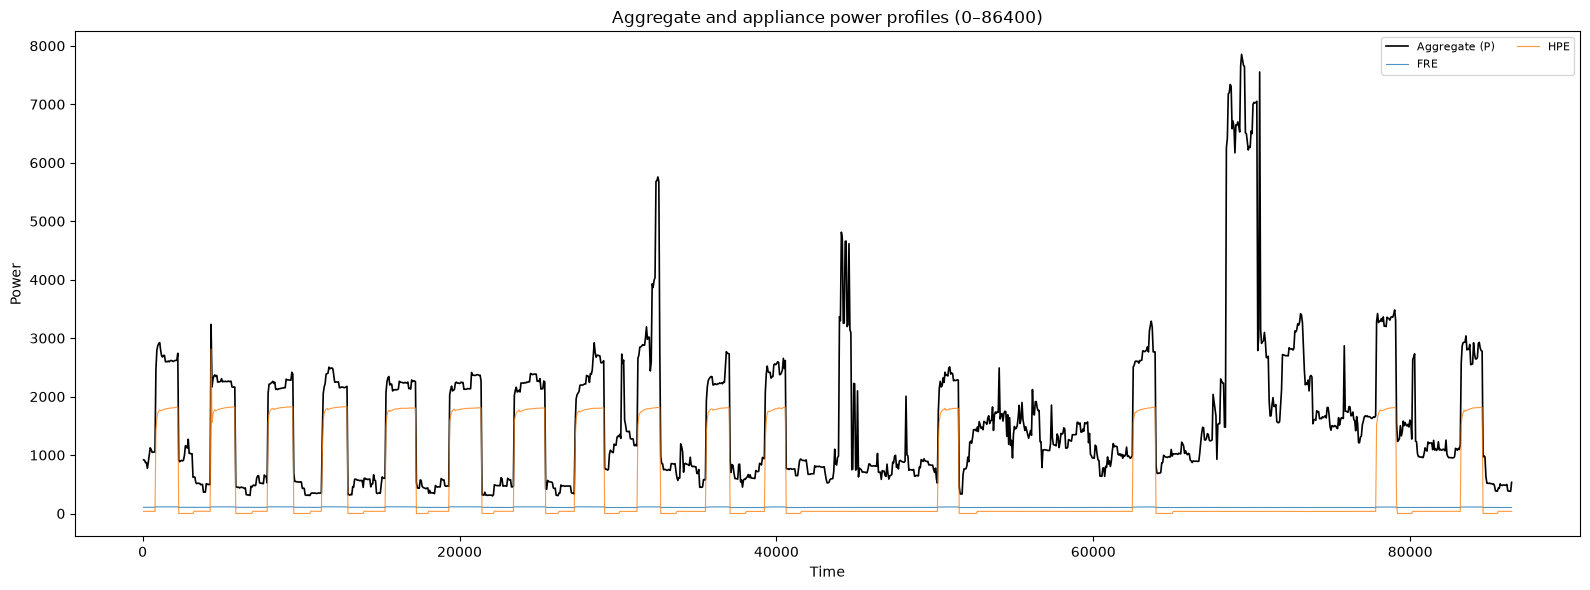

In [65]:
hours_to_plot = 24
t_start, t_end = 0, 3600 * hours_to_plot

mask = (datetimes >= t_start) & (datetimes <= t_end)
t = datetimes[mask]
p_agg = agg[mask, 0]  # active power P

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(t, p_agg, color='k', lw=1.2, label='Aggregate (P)')
for i, name in enumerate(appliance_names):
    ax.plot(t, apps[mask, i], lw=0.8, alpha=0.8, label=name)

ax.set_xlabel('Time')
ax.set_ylabel('Power')
ax.set_title(f'Aggregate and appliance power profiles ({t_start}–{t_end})')
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

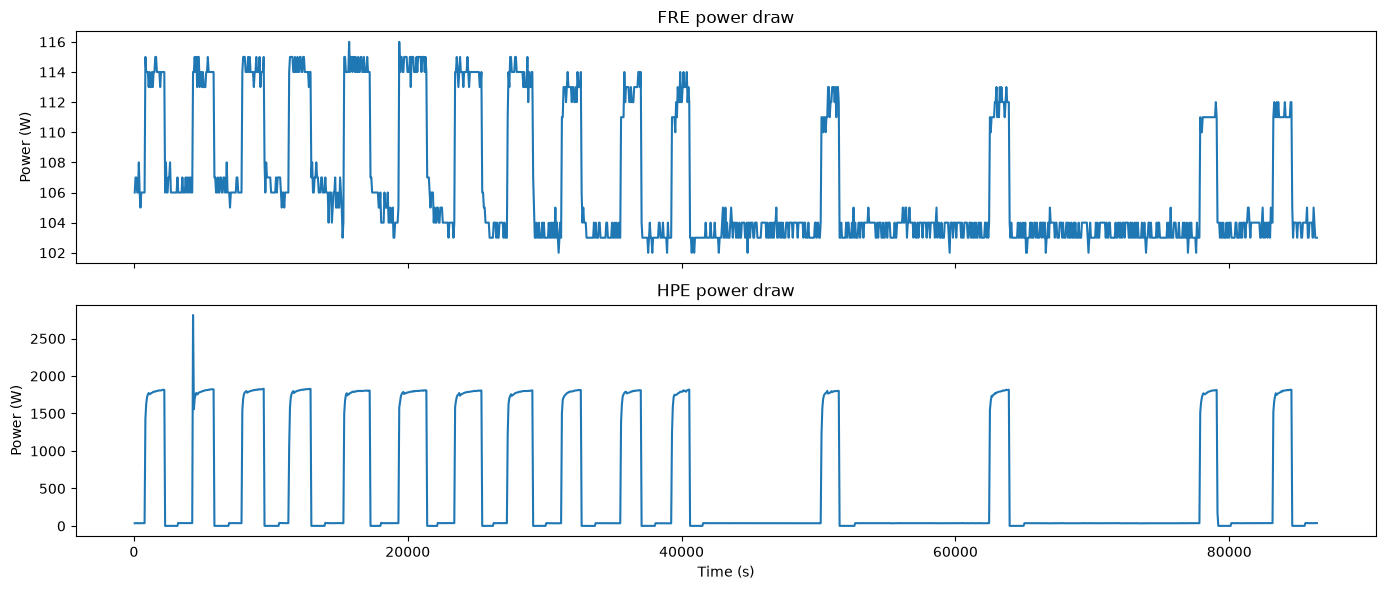

In [66]:
hours_to_plot = 24
t_start, t_end = 0, 3600 * hours_to_plot

mask = (datetimes >= t_start) & (datetimes <= t_end)
time_vals = datetimes[mask]

n = len(appliance_names)
fig, axes = plt.subplots(n, 1, figsize=(14, 3 * n), sharex=True)
axes = np.atleast_1d(axes)

for idx, (ax, name) in enumerate(zip(axes, appliance_names)):
    series = apps[mask, idx]
    ax.plot(time_vals, series, color="tab:blue")
    ax.set_title(f"{name} power draw")
    ax.set_ylabel("Power (W)")

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [67]:
display(metrics_df.style.format("{:.2f}").set_caption("Appliance Metrics"))

,apps_min,apps_max,apps_mean,apps_median,apps_std,apps_energy
FRE,0.00,581.00,115.41,110.00,28.68,121018264.00
HPE,0.00,3701.00,167.95,38.00,472.89,176109866.00


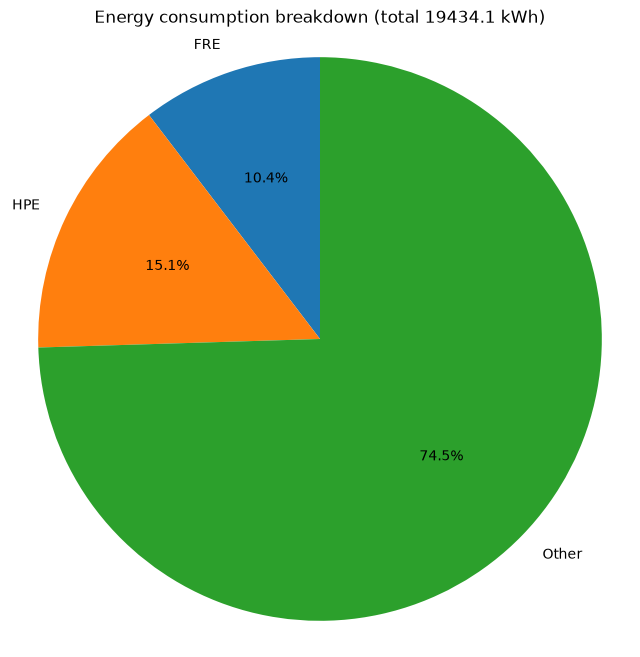

In [68]:
app_energy = appliance_metrics['apps_energy'] * time_resolution / 3.6e6
other_energy = agg_energy_kwh - app_energy.sum()

labels = list(appliance_names) + ['Other']
sizes = list(app_energy) + [max(other_energy, 0)]

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title(f'Energy consumption breakdown (total {agg_energy_kwh:.1f} kWh)')
plt.axis('equal')
plt.show()

## Create NILM Dataset

We need to divide the time-series data into training, validation, and testing sets. Randomly assigning individual timesteps would disrupt the temporal patterns the model needs to learn. However, using a single contiguous split could leave the training and testing sets with very different distributions. Instead, we divide the series into chunks, assinging entire chunks to each splits, and then shuffling the windows within each split.

### Precompute indices

We will use this data to train a sequence-to-point model, which takes a time-series window as input and predicts a single target value. Since these windows overlap substantially, creating and storing every window at once could consume too much memory. Instead, we keep the data unwindowed, store the window incides, and assign those indices to the training, validation, and test sets.

This function creates train, validation, and test examples from the time-series data without letting and timestamp belong simultaneously to multiple splits.

1. **Divide the timeline into chunks**: `boundaries` marks the edges of `num_chunks` contiguous chunks. If the timeline lenfth doesn't divide evenly by the number of chunks, some chunks get one extra timestep.

2. **Randomly assign chunks to splits**: `chunk_counts` allocates whole chunks to the train/validation/test splits, as close as possible to the requested proportions. 

3. **Make windows inside each assigned chunk**: Each `inp_idx` is a window's start position. Its matching `out_idx` is the window's center position. Only windows fully inside a chunk are included. This prevents chunks from simultaneously belonging to multiple splits.

4. **Shuffle exmaples within each split.**

5. **Return the results**: `idx_dict` maps each split name to `(input_indices, output_indices)`. `num_windows` is the total number of valid examples across all splits.

In [69]:
def precompute_indices(
    num_timesteps,
    window_length,
    stride,
    train_val_test_split,
    num_chunks,
    seed=42):

    expected_num_windows = max(0, (num_timesteps - window_length) // stride + 1)

    # Divide the timeline into contiguous, non-overlapping chunks.
    boundaries = np.linspace(0, num_timesteps, num_chunks + 1, dtype=int)
    chunk_ids = np.random.default_rng(seed).permutation(num_chunks)

    # Allocate whole chunks to splits, as close as possible to the requested ratios.
    exact_counts = np.asarray(train_val_test_split) * num_chunks
    chunk_counts = np.floor(exact_counts).astype(int)
    remainder = num_chunks - chunk_counts.sum()
    chunk_counts[np.argsort(-(exact_counts - chunk_counts))[:remainder]] += 1

    split_names = ("train", "val", "test")
    idx_dict = {}
    chunk_offset = 0

    for split_name, chunk_count in zip(split_names, chunk_counts):
        split_chunk_ids = chunk_ids[chunk_offset:chunk_offset + chunk_count]
        chunk_offset += chunk_count

        inp_parts = []

        for chunk_id in split_chunk_ids:
            chunk_start = boundaries[chunk_id]
            chunk_end = boundaries[chunk_id + 1]

            # Keep only windows fully contained in this chunk.
            starts = np.arange(
                chunk_start,
                chunk_end - window_length + 1,
                stride,
            )
            inp_parts.append(starts)

        inp_idx = np.concatenate(inp_parts) if inp_parts else np.array([], dtype=int)

        # Shuffle examples within each split.
        perm = np.random.default_rng(seed + len(idx_dict)).permutation(len(inp_idx))
        idx_dict[split_name + '_indices'] = inp_idx[perm]

    num_windows = sum(len(indices) for indices in idx_dict.values())
    return expected_num_windows, num_windows, idx_dict


In [70]:
expected_num_windows, num_windows, idx_dict = precompute_indices(T, window_length, stride, train_val_test_split, num_chunks, seed=42)
print(f'Number of Chunks Used: {num_chunks}')
print(f'Numer of Expected Windows: {expected_num_windows}')
print(f'Number of Windows Used: {num_windows}')
print(f'Number of Windows Discarded: {expected_num_windows - num_windows}')

Number of Chunks Used: 728
Numer of Expected Windows: 34952
Number of Windows Used: 34944
Number of Windows Discarded: 8


In [71]:
# Show the number of windows and unique timestamps covered in each split
print(f'Total Available Timestamps: {T}')
for split_name, starts in idx_dict.items():
    timestamps = np.unique((starts[:, None] + np.arange(window_length)).ravel())
    print(f"{split_name.capitalize():5} : {len(starts):3} windows, "
          f"{len(timestamps):3} unique timestamps")

Total Available Timestamps: 1048575
Train_indices : 24480 windows, 734400 unique timestamps
Val_indices : 5232 windows, 156960 unique timestamps
Test_indices : 5232 windows, 156960 unique timestamps


In [72]:
# Recompute the train/validation/test proportions from the assigned windows.
split_names = ("train_indices", "val_indices", "test_indices")
total = sum(len(idx_dict[name]) for name in split_names)

real_train_val_test_split = [
    len(idx_dict[name]) / total for name in split_names]

# calculate real number of unique timestamps used in whole dataset
all_starts = np.concatenate([idx_dict[name] for name in split_names])
all_timestamps = np.unique(
    np.concatenate([
        np.arange(start, start + window_length)
        for start in all_starts]))
real_num_unique_timestamps = len(all_timestamps)

print(f'Unique timestamps used across all splits: {real_num_unique_timestamps}')
print(f'Real Train/Val/Test Split: {real_train_val_test_split}')

Unique timestamps used across all splits: 1048320
Real Train/Val/Test Split: [0.7005494505494505, 0.14972527472527472, 0.14972527472527472]


## Normalize Data

Min–max normalization rescales each feature using its own minimum and maximum:

$
x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$

This maps values to roughly 0–1. The `1e-8` term prevents division by zero when a feature is constant. It’s often used before machine-learning training so features with larger numeric ranges don’t dominate, and to help some models train more reliably. To prevent information leakage, we calculate min/max on the training data, then reuse those same values for validation and test data. We save the min/max values of each electrical quantity and appliance. This will allow us to reconstruct the original data from normalized values later.

In [73]:
def normalize_data(x, train_indices, window_length):
    # All timesteps covered by any training window
    train_timesteps = np.unique((train_indices[:, None] + np.arange(window_length)).ravel())
    x_train = x[train_timesteps]

    x_min = x_train.min(axis=0, keepdims=True)
    x_max = x_train.max(axis=0, keepdims=True)
    x_norm = (x - x_min) / (x_max - x_min + 1e-8)
    return x_norm, x_min.ravel(), x_max.ravel()

In [74]:
# Normalize using min/max from training data only, then reattach time/id columns
train_indices = idx_dict['train_indices']

agg_p_norm, agg_min, agg_max = normalize_data(agg[:, 2:], train_indices, window_length)
apps_p_norm, apps_min_train, apps_max_train = normalize_data(apps[:, 2:], train_indices, window_length)

scaling_factors = {
    'apps_min': apps_min_train,
    'apps_max': apps_max_train}

agg_norm = np.column_stack((agg, agg_p_norm))
apps_norm = np.column_stack((apps, apps_p_norm))

### Save dataset

`ampds_dataset.npz` is a compressed NumPy archive containing:
- `agg` and `agg_norm`: correct-scale aggregate and appliance-level data.
-  `agg_norm` and `apps_norm`: normalized aggregate and appliance-level data.
- `scaling factors`: The min/max values used to normalize `agg` and `apps`, for reversing the normalization later. 
- `idx_dict`: Maps each split to an index array. The indices mark where each window starts.
- `T`, `train_val_test_split`, `window_length`, `stride`: parameters describing the number of timesteps, split proportions, and windowing setup.

In [76]:
dataset_path = os.path.join(processed_data_dir, 'ampds_pattern-matching_full.npz')

np.savez_compressed(
    dataset_path,
    agg_labels=agg_labels,
    apps_labels=apps_labels,
    electrical_quantities=electrical_quantities,
    appliance_names=appliance_names,
    datetimes=datetimes,
    agg_data=agg,
    apps_data=apps,
    agg_norm=agg_norm,
    apps_norm=apps_norm,
    **scaling_factors,
    **idx_dict,
    train_val_test_split=real_train_val_test_split,
    T=real_num_unique_timestamps,
    window_length=window_length,
    stride=stride,
    chunk_size=chunk_size,
    num_chunks=num_chunks,
    time_resolution=time_resolution,
    time_units=time_units)